- Used machine learning to predict whether airline passengers are satisfied or unsatisfied.
- Cleaned the data, used statistical tests (Chi-Square & ANOVA) to select the most important features, and handled class imbalance using undersampling. 
- Built and evaluated several classifiers, with our optimized CatBoost model achieving the highest predictive accuracy of ~96% on test data.


In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [2]:
df = pd.read_csv('datasets/Airline-Satisfaction-Data.csv')

In [3]:
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [4]:
df['satisfaction'].unique()

array([False,  True])

In [5]:
df.shape

(129880, 22)

In [6]:
df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  str    
 1   Customer Type                      129880 non-null  str    
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  str    
 4   Class                              129880 non-null  str    
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    129880 non-null

In [8]:
df.isnull().sum()

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction                           0
dtype: int64

In [ ]:
df['Arrival Delay in Minutes'].unique()

array([1.800e+01, 6.000e+00, 0.000e+00, 9.000e+00, 2.300e+01, 8.000e+00,
       3.500e+01, 5.100e+01, 1.000e+01, 5.000e+00, 4.000e+00, 2.900e+01,
       4.400e+01, 2.800e+01, 1.200e+01, 1.200e+02, 2.400e+01, 1.000e+00,
       2.000e+01, 3.100e+01, 1.500e+01, 4.800e+01, 2.600e+01, 4.900e+01,
       2.000e+00, 3.700e+01, 5.000e+01, 3.000e+00, 1.900e+01, 7.200e+01,
       1.100e+01, 3.400e+01, 6.200e+01, 2.700e+01, 5.200e+01, 1.300e+01,
       8.200e+01, 3.000e+01, 1.600e+01, 7.000e+00, 1.220e+02, 1.790e+02,
       1.250e+02, 1.700e+01,       nan, 8.900e+01, 1.010e+02, 1.400e+01,
       6.100e+01, 3.200e+01, 3.300e+01, 4.100e+01, 1.910e+02, 1.380e+02,
       5.300e+01, 2.200e+01, 5.700e+01, 6.500e+01, 7.600e+01, 1.070e+02,
       9.200e+01, 1.640e+02, 2.100e+01, 4.000e+01, 5.500e+01, 1.850e+02,
       6.300e+01, 7.700e+01, 8.600e+01, 9.100e+01, 1.000e+02, 5.400e+01,
       3.600e+01, 7.000e+01, 1.390e+02, 6.700e+01, 1.630e+02, 1.280e+02,
       1.800e+02, 9.300e+01, 1.210e+02, 4.500e+01, 

In [10]:
df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].mean())

In [11]:
df.isnull().sum()

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df = df.rename(columns={
    'Flight Distance': 'Flight_Distance',
    'Inflight wifi service': 'Inflight_wifi_service',
    'Departure/Arrival time convenient': 'Departure_Arrival_time_convenient',
    'Ease of Online booking': 'Ease_of_Online_booking',
    'Gate location': 'Gate_location',
    'Food and drink': 'Food_and_drink',
    'Online boarding': 'Online_boarding',
    'Seat comfort': 'Seat_comfort',
    'Inflight entertainment': 'Inflight_entertainment',
    'On-board service': 'On_board_service',
    'Leg room service': 'Leg_room_service',
    'Baggage handling': 'Baggage_handling',
    'Departure Delay in Minutes': 'Departure_Delay_in_Minutes',
    'Arrival Delay in Minutes': 'Arrival_Delay_in_Minutes',
    'Checkin service': 'Checkin_service',
})

In [14]:
cat_cols = df.select_dtypes(include=object).columns.tolist()
cat_cols


/var/folders/7b/5_gy8f1j7171y56xbfvy4r7h0000gn/T/ipykernel_79484/4045066859.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=object).columns.tolist()


['Gender', 'Customer Type', 'Type of Travel', 'Class']

In [15]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Gender'], df['satisfaction'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')


satisfaction  False  True 
Gender                    
Female        37630  28269
Male          35822  28159
chi2: 16.35, p-value: 0.0001, alpha: 0.05, significant: True, DOF: 1


In [16]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Customer Type'], df['satisfaction'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')


satisfaction       False  True 
Customer Type                  
Loyal Customer     55372  50728
disloyal Customer  18080   5700
chi2: 4493.19, p-value: 0.0000, alpha: 0.05, significant: True, DOF: 1


In [17]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Type of Travel'], df['satisfaction'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')


satisfaction     False  True 
Type of Travel               
Business travel  37337  52356
Personal Travel  36115   4072
chi2: 26282.52, p-value: 0.0000, alpha: 0.05, significant: True, DOF: 1


In [18]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Class'], df['satisfaction'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, \nsignificant: {p < alpha}, DOF: {dof}')


satisfaction  False  True 
Class                     
Business      18994  43166
Eco           47366  10943
Eco Plus       7092   2319
chi2: 32906.17, p-value: 0.0000, alpha: 0.05, 
significant: True, DOF: 2


In [19]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols


['Age',
 'Flight_Distance',
 'Inflight_wifi_service',
 'Departure_Arrival_time_convenient',
 'Ease_of_Online_booking',
 'Gate_location',
 'Food_and_drink',
 'Online_boarding',
 'Seat_comfort',
 'Inflight_entertainment',
 'On_board_service',
 'Leg_room_service',
 'Baggage_handling',
 'Checkin_service',
 'Cleanliness',
 'Departure_Delay_in_Minutes',
 'Arrival_Delay_in_Minutes']

In [20]:
df['Gate_location'].unique()

array([1, 3, 2, 5, 4, 0])

In [21]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Age ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df        sum_sq        mean_sq            F  PR(>F)
C(satisfaction)       1.0  5.338344e+05  533834.397969  2378.024191     0.0
Residual         129878.0  2.915586e+07     224.486530          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [22]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Flight_Distance ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df        sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0  1.148162e+10  1.148162e+10  12665.660936     0.0
Residual         129878.0  1.177365e+11  9.065160e+05           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [23]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Inflight_wifi_service ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   18441.465968  18441.465968  11347.420455     0.0
Residual         129878.0  211073.585087      1.625168           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [24]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Departure_Arrival_time_convenient ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq     mean_sq           F        PR(>F)
C(satisfaction)       1.0     891.630588  891.630588  383.646795  2.657334e-85
Residual         129878.0  301848.468881    2.324092         NaN           NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [25]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Ease_of_Online_booking ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq      mean_sq            F  PR(>F)
C(satisfaction)       1.0    7278.055294  7278.055294  3812.792979     0.0
Residual         129878.0  247917.804815     1.908851          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [26]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Gate_location ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq   mean_sq         F  PR(>F)
C(satisfaction)       1.0       1.656460  1.656460  1.013366  0.3141
Residual         129878.0  212300.187326  1.634612       NaN     NaN
C(satisfaction)    False
Residual           False
Name: PR(>F), dtype: bool


In [27]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Food_and_drink ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq            F  PR(>F)
C(satisfaction)       1.0   10260.363930  10260.363930  6072.171356     0.0
Residual         129878.0  219459.476415      1.689736          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [28]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Online_boarding ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   59654.411850  59654.411850  43698.252161     0.0
Residual         129878.0  177302.187596      1.365144           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [29]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Seat_comfort ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   27507.097704  27507.097704  17993.257439     0.0
Residual         129878.0  198550.309625      1.528745           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [30]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Inflight_entertainment ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   36657.124828  36657.124828  24479.573892     0.0
Residual         129878.0  194486.802728      1.497458           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [31]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'On_board_service ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   22337.118864  22337.118864  15045.355578     0.0
Residual         129878.0  192823.646389      1.484652           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [32]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Leg_room_service ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   21963.682100  21963.682100  14048.467148     0.0
Residual         129878.0  203054.117838      1.563422           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [33]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Baggage_handling ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq            F  PR(>F)
C(satisfaction)       1.0   11184.136829  11184.136829  8561.323382     0.0
Residual         129878.0  169666.914595      1.306356          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [34]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Checkin_service  ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq            F  PR(>F)
C(satisfaction)       1.0   11720.727704  11720.727704  7746.713816     0.0
Residual         129878.0  196504.570694      1.512994          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [35]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Cleanliness ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   21129.753372  21129.753372  13517.980514     0.0
Residual         129878.0  203010.361318      1.563085           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [36]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Departure_Delay_in_Minutes ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df        sum_sq        mean_sq           F  \
C(satisfaction)       1.0  4.846509e+05  484650.891230  335.238409   
Residual         129878.0  1.877634e+08    1445.690225         NaN   

                       PR(>F)  
C(satisfaction)  8.634339e-75  
Residual                  NaN  
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [37]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Arrival_Delay_in_Minutes ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df        sum_sq        mean_sq           F  \
C(satisfaction)       1.0  6.486752e+05  648675.196423  441.231827   
Residual         129878.0  1.909396e+08    1470.145979         NaN   

                       PR(>F)  
C(satisfaction)  8.501049e-98  
Residual                  NaN  
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [38]:
df.shape

(129880, 22)

In [39]:
df = df.drop('Gate_location', axis=1)

In [40]:
df.shape

(129880, 21)

In [41]:
df

,Gender,Customer Type,Age,Type of Travel,Class,Flight_Distance,Inflight_wifi_service,Departure_Arrival_time_convenient,Ease_of_Online_booking,Food_and_drink,...,Seat_comfort,Inflight_entertainment,On_board_service,Leg_room_service,Baggage_handling,Checkin_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,5,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,1,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,5,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,2,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,4,...,5,3,3,4,4,3,3,0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,Male,disloyal Customer,34,Business travel,Business,526,3,3,3,4,...,4,4,3,2,4,4,4,0,0.0,False
129876,Male,Loyal Customer,23,Business travel,Business,646,4,4,4,4,...,4,4,4,5,5,5,4,0,0.0,True
129877,Female,Loyal Customer,17,Personal Travel,Eco,828,2,5,1,2,...,2,2,4,3,4,5,2,0,0.0,False
129878,Male,Loyal Customer,14,Business travel,Business,1127,3,3,3,4,...,4,4,3,2,5,4,4,0,0.0,True


In [42]:
# df['satisfaction'].value_counts()

In [43]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# sns.countplot(x='satisfaction', data=df)

In [44]:
# from imblearn.under_sampling import RandomUnderSampler

# x = df.drop('satisfaction', axis=1)
# y = df['satisfaction']
# underSamp = RandomUnderSampler()
# x_samp, y_samp = underSamp.fit_resample(x, y)

# y_samp.value_counts()

In [45]:
df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight_Distance', 'Inflight_wifi_service',
       'Departure_Arrival_time_convenient', 'Ease_of_Online_booking',
       'Food_and_drink', 'Online_boarding', 'Seat_comfort',
       'Inflight_entertainment', 'On_board_service', 'Leg_room_service',
       'Baggage_handling', 'Checkin_service', 'Cleanliness',
       'Departure_Delay_in_Minutes', 'Arrival_Delay_in_Minutes',
       'satisfaction'],
      dtype='str')

In [46]:
df.shape

(129880, 21)

In [47]:
from sklearn.preprocessing import OrdinalEncoder
o = OrdinalEncoder()
df[['Gender']] = o.fit_transform(df[['Gender']])
df[['Customer Type']] = o.fit_transform(df[['Customer Type']])
df[['Type of Travel']] = o.fit_transform(df[['Type of Travel']])
df[['Age']] = o.fit_transform(df[['Age']])
df[['Class']] = o.fit_transform(df[['Class']])
df[['Flight_Distance']] = o.fit_transform(df[['Flight_Distance']])
df[['Inflight_wifi_service']] = o.fit_transform(df[['Inflight_wifi_service']])
df[['Departure_Arrival_time_convenient']] = o.fit_transform(df[['Departure_Arrival_time_convenient']])
df[['Ease_of_Online_booking']] = o.fit_transform(df[['Ease_of_Online_booking']])
df[['Food_and_drink']] = o.fit_transform(df[['Food_and_drink']])
df[['Online_boarding']] = o.fit_transform(df[['Online_boarding']])
df[['Seat_comfort']] = o.fit_transform(df[['Seat_comfort']])
df[['Inflight_entertainment']] = o.fit_transform(df[['Inflight_entertainment']])
df[['On_board_service']] = o.fit_transform(df[['On_board_service']])
df[['Leg_room_service']] = o.fit_transform(df[['Leg_room_service']])
df[['Baggage_handling']] = o.fit_transform(df[['Baggage_handling']])
df[['Checkin_service']] = o.fit_transform(df[['Checkin_service']])
df[['Cleanliness']] = o.fit_transform(df[['Cleanliness']])
df[['Departure_Delay_in_Minutes']] = o.fit_transform(df[['Departure_Delay_in_Minutes']])
df[['Arrival_Delay_in_Minutes']] = o.fit_transform(df[['Arrival_Delay_in_Minutes']])

In [48]:
from sklearn.preprocessing import LabelEncoder
o = LabelEncoder()
df['satisfaction'] = o.fit_transform(df['satisfaction'])

In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  float64
 1   Customer Type                      129880 non-null  float64
 2   Age                                129880 non-null  float64
 3   Type of Travel                     129880 non-null  float64
 4   Class                              129880 non-null  float64
 5   Flight_Distance                    129880 non-null  float64
 6   Inflight_wifi_service              129880 non-null  float64
 7   Departure_Arrival_time_convenient  129880 non-null  float64
 8   Ease_of_Online_booking             129880 non-null  float64
 9   Food_and_drink                     129880 non-null  float64
 10  Online_boarding                    129880 non-null  float64
 11  Seat_comfort                       129880 non-null

In [50]:
df['satisfaction'].value_counts()

satisfaction
0    73452
1    56428
Name: count, dtype: int64

<Axes: xlabel='satisfaction', ylabel='count'>

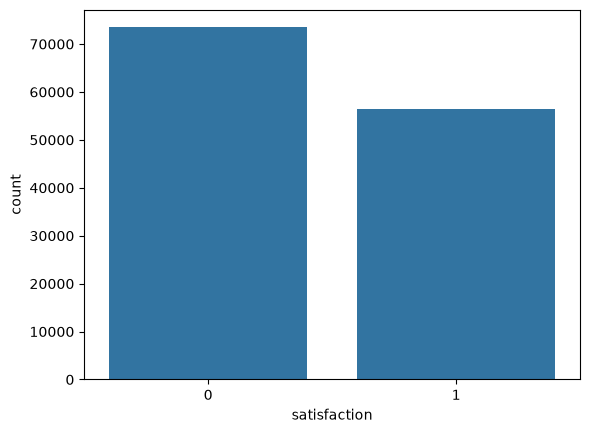

In [51]:
sns.countplot(x='satisfaction', data=df)

In [52]:
x = df.drop('satisfaction', axis=1)
y = df['satisfaction']

In [53]:
from imblearn.under_sampling import RandomUnderSampler  

underSamp = RandomUnderSampler()
x_samp, y_samp = underSamp.fit_resample(x, y)

print(y_samp.value_counts())

satisfaction
0    56428
1    56428
Name: count, dtype: int64


In [54]:
from sklearn.model_selection import train_test_split
x_samp_train, x_samp_test, y_samp_train, y_samp_test = train_test_split(x_samp,y_samp, test_size=0.20,random_state=42)
print(x_samp_train.shape)
print(x_samp_test.shape)
print(y_samp_train.shape)
print(y_samp_test.shape)

(90284, 20)
(22572, 20)
(90284,)
(22572,)


In [55]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

x_train_scaled = scaler.fit_transform(x_samp_train)
x_test_scaled = scaler.transform(x_samp_test)

print("Scaling Done!")
print("x_train_scaled shape:", x_train_scaled.shape)

Scaling Done!
x_train_scaled shape: (90284, 20)


In [56]:
# Model training and evaluation 
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_samp_train, y_samp_train)

y_pred_train = lr.predict(x_train_scaled)
print("Model trained successfully!")
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print(accuracy_score(y_samp_train, y_pred_train))
print(confusion_matrix(y_samp_train, y_pred_train))
print(classification_report(y_samp_train, y_pred_train))

Model trained successfully!
0.7415931948074963
[[43256  1742]
 [21588 23698]]
              precision    recall  f1-score   support

           0       0.67      0.96      0.79     44998
           1       0.93      0.52      0.67     45286

    accuracy                           0.74     90284
   macro avg       0.80      0.74      0.73     90284
weighted avg       0.80      0.74      0.73     90284



/Users/sudharsank/AIML/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/sudharsank/AIML/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [57]:
# predict
y_pred = lr.predict(x_test_scaled)
print("Predictions:", y_pred)

# evaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy: ", accuracy_score(y_samp_test, y_pred))
print(confusion_matrix(y_samp_test, y_pred))
print(classification_report(y_samp_test, y_pred))

Predictions: [1 0 0 ... 0 1 0]
Accuracy:  0.7485380116959064
[[10988   442]
 [ 5234  5908]]
              precision    recall  f1-score   support

           0       0.68      0.96      0.79     11430
           1       0.93      0.53      0.68     11142

    accuracy                           0.75     22572
   macro avg       0.80      0.75      0.74     22572
weighted avg       0.80      0.75      0.74     22572



/Users/sudharsank/AIML/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [58]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()

dt.fit(x_samp_train, y_samp_train)

y_pred_dt_train = dt.predict(x_samp_train)

print("Decision Tree trained successfully!")

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print(accuracy_score(y_samp_train, y_pred_dt_train))
print(confusion_matrix(y_samp_train, y_pred_dt_train))
print(classification_report(y_samp_train, y_pred_dt_train))

Decision Tree trained successfully!
1.0
[[44998     0]
 [    0 45286]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     44998
           1       1.00      1.00      1.00     45286

    accuracy                           1.00     90284
   macro avg       1.00      1.00      1.00     90284
weighted avg       1.00      1.00      1.00     90284



In [59]:
# DecisionTree - Testing
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_dt=dt.predict(x_samp_test)

print(accuracy_score(y_samp_test, y_pred_dt))
print(confusion_matrix(y_samp_test, y_pred_dt))
print(classification_report(y_samp_test, y_pred_dt))

0.9385521885521886
[[10701   729]
 [  658 10484]]
              precision    recall  f1-score   support

           0       0.94      0.94      0.94     11430
           1       0.93      0.94      0.94     11142

    accuracy                           0.94     22572
   macro avg       0.94      0.94      0.94     22572
weighted avg       0.94      0.94      0.94     22572



In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

rf = RandomForestClassifier()

rf.fit(x_samp_train, y_samp_train)

y_train_predict = rf.predict(x_samp_train)

# Evaluation - train
print("Random Forest accuracy:", accuracy_score(y_samp_train, y_train_predict))
print("Confusion matrix:\n", confusion_matrix(y_samp_train, y_train_predict))
print("Classification report:\n", classification_report(y_samp_train, y_train_predict))


Random Forest accuracy: 0.9999889238403261
Confusion matrix:
 [[44998     0]
 [    1 45285]]
Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     44998
           1       1.00      1.00      1.00     45286

    accuracy                           1.00     90284
   macro avg       1.00      1.00      1.00     90284
weighted avg       1.00      1.00      1.00     90284



In [61]:
# Predict on the test data
y_pred_rf = rf.predict(x_samp_test)

# Evaluation - test
print("Random Forest accuracy:", accuracy_score(y_samp_test, y_pred_rf))
print("Confusion matrix:\n", confusion_matrix(y_samp_test, y_pred_rf))
print("Classification report:\n", classification_report(y_samp_test, y_pred_rf))

Random Forest accuracy: 0.955431508063087
Confusion matrix:
 [[11047   383]
 [  623 10519]]
Classification report:
               precision    recall  f1-score   support

           0       0.95      0.97      0.96     11430
           1       0.96      0.94      0.95     11142

    accuracy                           0.96     22572
   macro avg       0.96      0.96      0.96     22572
weighted avg       0.96      0.96      0.96     22572



In [62]:
from catboost import CatBoostClassifier
cb = CatBoostClassifier()

cb.fit(x_samp_train, y_samp_train)

y_train_predict = cb.predict(x_samp_train)

# Evaluation - train
print("Accuracy:", accuracy_score(y_samp_train, y_train_predict))
print("Confusion matrix:\n", confusion_matrix(y_samp_train, y_train_predict))
print("Classification report:\n", classification_report(y_samp_train, y_train_predict))

Learning rate set to 0.070466
0:	learn: 0.5994852	total: 65.9ms	remaining: 1m 5s
1:	learn: 0.4985682	total: 73.9ms	remaining: 36.9s
2:	learn: 0.4430216	total: 81.6ms	remaining: 27.1s
3:	learn: 0.3879779	total: 89ms	remaining: 22.2s
4:	learn: 0.3503732	total: 95.9ms	remaining: 19.1s
5:	learn: 0.3218270	total: 103ms	remaining: 17s
6:	learn: 0.2963758	total: 109ms	remaining: 15.5s
7:	learn: 0.2800840	total: 116ms	remaining: 14.4s
8:	learn: 0.2667814	total: 123ms	remaining: 13.6s
9:	learn: 0.2552151	total: 130ms	remaining: 12.9s
10:	learn: 0.2386547	total: 137ms	remaining: 12.3s
11:	learn: 0.2271791	total: 144ms	remaining: 11.9s
12:	learn: 0.2160209	total: 151ms	remaining: 11.4s
13:	learn: 0.2078209	total: 158ms	remaining: 11.1s
14:	learn: 0.2019318	total: 164ms	remaining: 10.8s
15:	learn: 0.1972394	total: 172ms	remaining: 10.6s
16:	learn: 0.1928724	total: 178ms	remaining: 10.3s
17:	learn: 0.1880937	total: 186ms	remaining: 10.1s
18:	learn: 0.1846906	total: 192ms	remaining: 9.9s
19:	learn: 

In [63]:
y_pred_rf = rf.predict(x_samp_test)

# Evaluation - test
print("accuracy:", accuracy_score(y_samp_test, y_pred_rf))
print("Confusion matrix:\n", confusion_matrix(y_samp_test, y_pred_rf))
print("Classification report:\n", classification_report(y_samp_test, y_pred_rf))

accuracy: 0.955431508063087
Confusion matrix:
 [[11047   383]
 [  623 10519]]
Classification report:
               precision    recall  f1-score   support

           0       0.95      0.97      0.96     11430
           1       0.96      0.94      0.95     11142

    accuracy                           0.96     22572
   macro avg       0.96      0.96      0.96     22572
weighted avg       0.96      0.96      0.96     22572



In [64]:
from sklearn.neighbors import KNeighborsClassifier  
kn=KNeighborsClassifier()

x_train_scaled_kn = scaler.fit_transform(x_samp_train)
x_test_scaled_kn = scaler.transform(x_samp_test)

kn.fit(x_train_scaled_kn, y_samp_train)

y_pred = kn.predict(x_test_scaled_kn)
y_pred

# Evaluation - train
print("Random Forest accuracy:", accuracy_score(y_samp_train, y_train_predict))
print("Confusion matrix:\n", confusion_matrix(y_samp_train, y_train_predict))
print("Classification report:\n", classification_report(y_samp_train, y_train_predict))

Random Forest accuracy: 0.9732067697487927
Confusion matrix:
 [[44136   862]
 [ 1557 43729]]
Classification report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97     44998
           1       0.98      0.97      0.97     45286

    accuracy                           0.97     90284
   macro avg       0.97      0.97      0.97     90284
weighted avg       0.97      0.97      0.97     90284



In [65]:
y_pred_rf = rf.predict(x_test_scaled_kn)

# Evaluation - test
print("Random Forest accuracy:", accuracy_score(y_samp_test, y_pred_rf))
print("Confusion matrix:\n", confusion_matrix(y_samp_test, y_pred_rf))
print("Classification report:\n", classification_report(y_samp_test, y_pred_rf))

Random Forest accuracy: 0.4076289207868155
Confusion matrix:
 [[5458 5972]
 [7399 3743]]
Classification report:
               precision    recall  f1-score   support

           0       0.42      0.48      0.45     11430
           1       0.39      0.34      0.36     11142

    accuracy                           0.41     22572
   macro avg       0.40      0.41      0.40     22572
weighted avg       0.41      0.41      0.40     22572



/Users/sudharsank/AIML/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [66]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

nb = GaussianNB()
nb.fit(x_samp_train, y_samp_train)

y_pred_nb = nb.predict(x_samp_train)
print(accuracy_score(y_samp_train, y_pred_nb))
print(classification_report(y_samp_train, y_pred_nb))

0.8601413317974392
              precision    recall  f1-score   support

           0       0.84      0.89      0.86     44998
           1       0.88      0.83      0.86     45286

    accuracy                           0.86     90284
   macro avg       0.86      0.86      0.86     90284
weighted avg       0.86      0.86      0.86     90284



In [67]:
y_pred_nb = nb.predict(x_samp_test)
print(accuracy_score(y_samp_test, y_pred_nb))
print(classification_report(y_samp_test, y_pred_nb))

0.8566365408470672
              precision    recall  f1-score   support

           0       0.84      0.89      0.86     11430
           1       0.88      0.83      0.85     11142

    accuracy                           0.86     22572
   macro avg       0.86      0.86      0.86     22572
weighted avg       0.86      0.86      0.86     22572



In [68]:
# gaussianNB, catboost - normalized fit

In [69]:
df.shape

(129880, 21)

In [72]:
# gaussianNB, catboost - normalized fit -> hyperparamter tuning
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostClassifier

cat_param = {
    "iterations": [200, 400, 600, 800],
    "depth": [4, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5, 7, 9],
    "random_strength": [0, 1, 2, 5],
    "border_count": [32, 64, 128],
}

cb= CatBoostClassifier()
cb_cv = RandomizedSearchCV(cb, cat_param, cv=5)
cb_cv.fit(x_samp_train, y_samp_train)

print(cb_cv.best_params_)

0:	learn: 0.6401064	total: 13ms	remaining: 10.4s
1:	learn: 0.5814867	total: 21.5ms	remaining: 8.57s
2:	learn: 0.5378629	total: 28.9ms	remaining: 7.68s
3:	learn: 0.4965261	total: 35.9ms	remaining: 7.14s
4:	learn: 0.4633851	total: 42.2ms	remaining: 6.71s
5:	learn: 0.4257282	total: 54.1ms	remaining: 7.16s
6:	learn: 0.4021442	total: 65.7ms	remaining: 7.44s
7:	learn: 0.3714779	total: 73.3ms	remaining: 7.25s
8:	learn: 0.3555899	total: 79.6ms	remaining: 7s
9:	learn: 0.3290965	total: 88.9ms	remaining: 7.02s
10:	learn: 0.3140244	total: 96.1ms	remaining: 6.89s
11:	learn: 0.3025315	total: 103ms	remaining: 6.75s
12:	learn: 0.2865503	total: 112ms	remaining: 6.75s
13:	learn: 0.2746646	total: 119ms	remaining: 6.66s
14:	learn: 0.2656374	total: 126ms	remaining: 6.59s
15:	learn: 0.2560832	total: 134ms	remaining: 6.55s
16:	learn: 0.2455036	total: 140ms	remaining: 6.46s
17:	learn: 0.2393971	total: 148ms	remaining: 6.41s
18:	learn: 0.2346448	total: 154ms	remaining: 6.35s
19:	learn: 0.2279838	total: 161ms	r

In [73]:
# gaussianNB, catboost - normalized fit -> catboost -> hyperparamter tuning
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostClassifier

cat_param = {
    "iterations": [200, 400, 600, 800],
    "depth": [4, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5, 7, 9],
    "random_strength": [0, 1, 2, 5],
    "border_count": [32, 64, 128],
}

cb= CatBoostClassifier()
cb_cv = RandomizedSearchCV(cb, cat_param, cv=5)
cb_cv.fit(x_samp_test, y_samp_test)

print(cb_cv.best_params_)

0:	learn: 0.6822954	total: 3.64ms	remaining: 724ms
1:	learn: 0.6717637	total: 7.5ms	remaining: 742ms
2:	learn: 0.6615395	total: 11.1ms	remaining: 728ms
3:	learn: 0.6516240	total: 14.4ms	remaining: 708ms
4:	learn: 0.6420057	total: 17.4ms	remaining: 678ms
5:	learn: 0.6304956	total: 19.5ms	remaining: 630ms
6:	learn: 0.6194297	total: 21.8ms	remaining: 602ms
7:	learn: 0.6087926	total: 24ms	remaining: 577ms
8:	learn: 0.6003715	total: 26.5ms	remaining: 563ms
9:	learn: 0.5904102	total: 28.5ms	remaining: 542ms
10:	learn: 0.5808385	total: 30.6ms	remaining: 525ms
11:	learn: 0.5736780	total: 32.5ms	remaining: 510ms
12:	learn: 0.5646710	total: 35.2ms	remaining: 506ms
13:	learn: 0.5579062	total: 38.3ms	remaining: 508ms
14:	learn: 0.5494271	total: 40.8ms	remaining: 503ms
15:	learn: 0.5428661	total: 43.1ms	remaining: 496ms
16:	learn: 0.5362748	total: 45.3ms	remaining: 487ms
17:	learn: 0.5302075	total: 47.3ms	remaining: 479ms
18:	learn: 0.5241266	total: 50.3ms	remaining: 479ms
19:	learn: 0.5166079	tota

In [76]:
# train gaussian with cv given params
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

nb = CatBoostClassifier(
    random_strength = 1,
    learning_rate = 0.03,
    l2_leaf_reg=3,
    iterations=400,
    depth=10,
    border_count=128
)
nb.fit(x_samp_train, y_samp_train)

y_pred_nb = nb.predict(x_samp_train)
print(accuracy_score(y_samp_train, y_pred_nb))
print(classification_report(y_samp_train, y_pred_nb))

0:	learn: 0.6267124	total: 27.5ms	remaining: 11s
1:	learn: 0.5695124	total: 42.1ms	remaining: 8.38s
2:	learn: 0.5182630	total: 56.7ms	remaining: 7.51s
3:	learn: 0.4729944	total: 70.8ms	remaining: 7.01s
4:	learn: 0.4362681	total: 85.2ms	remaining: 6.73s
5:	learn: 0.4027434	total: 99.6ms	remaining: 6.54s
6:	learn: 0.3738603	total: 114ms	remaining: 6.38s
7:	learn: 0.3465207	total: 128ms	remaining: 6.25s
8:	learn: 0.3246276	total: 141ms	remaining: 6.13s
9:	learn: 0.3053123	total: 155ms	remaining: 6.06s
10:	learn: 0.2885093	total: 170ms	remaining: 6.01s
11:	learn: 0.2732217	total: 184ms	remaining: 5.95s
12:	learn: 0.2596318	total: 198ms	remaining: 5.9s
13:	learn: 0.2485746	total: 212ms	remaining: 5.85s
14:	learn: 0.2393911	total: 226ms	remaining: 5.8s
15:	learn: 0.2299871	total: 241ms	remaining: 5.78s
16:	learn: 0.2232032	total: 303ms	remaining: 6.83s
17:	learn: 0.2147374	total: 318ms	remaining: 6.74s
18:	learn: 0.2071071	total: 332ms	remaining: 6.66s
19:	learn: 0.2023948	total: 347ms	remai

In [77]:
# train gaussian with cv given params
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

nb = CatBoostClassifier(
    random_strength = 2,
    learning_rate = 0.03,
    l2_leaf_reg=3,
    iterations=600,
    depth=10,
    border_count=128
)
nb.fit(x_samp_train, y_samp_train)

y_pred_nb = nb.predict(x_samp_test)
print(accuracy_score(y_samp_test, y_pred_nb))
print(classification_report(y_samp_test, y_pred_nb))

0:	learn: 0.6288916	total: 21.9ms	remaining: 13.1s
1:	learn: 0.5742187	total: 42.4ms	remaining: 12.7s
2:	learn: 0.5247059	total: 57.6ms	remaining: 11.5s
3:	learn: 0.4833487	total: 72.2ms	remaining: 10.8s
4:	learn: 0.4437525	total: 86.4ms	remaining: 10.3s
5:	learn: 0.4080033	total: 99.9ms	remaining: 9.89s
6:	learn: 0.3787237	total: 114ms	remaining: 9.66s
7:	learn: 0.3520705	total: 128ms	remaining: 9.5s
8:	learn: 0.3327404	total: 143ms	remaining: 9.38s
9:	learn: 0.3149228	total: 158ms	remaining: 9.3s
10:	learn: 0.2963571	total: 172ms	remaining: 9.19s
11:	learn: 0.2810679	total: 185ms	remaining: 9.08s
12:	learn: 0.2664538	total: 200ms	remaining: 9.04s
13:	learn: 0.2538557	total: 215ms	remaining: 8.98s
14:	learn: 0.2447069	total: 228ms	remaining: 8.91s
15:	learn: 0.2361972	total: 245ms	remaining: 8.95s
16:	learn: 0.2285671	total: 268ms	remaining: 9.19s
17:	learn: 0.2193368	total: 282ms	remaining: 9.1s
18:	learn: 0.2121035	total: 297ms	remaining: 9.08s
19:	learn: 0.2065977	total: 312ms	rema